# Etapa 2 — Análise Exploratória de Dados

Entrada: os CSVs que a Etapa 1 gravou em `../data/raw/`.
Saída: uma tabela horária limpa em `../data/processed/dataset.csv`, mais os
gráficos e as conclusões que sustentam o que você vai afirmar.

As seções abaixo são um roteiro, não uma receita. Responda as perguntas de
cada uma com código e, no fim, em texto. Acrescente seções se quiser.

In [338]:
from pathlib import Path

DIR_RAW = Path("..") / "data" / "raw"
DIR_PROC = Path("..") / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)

# TODO: imports (pandas, matplotlib, seaborn, ...)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

## 1. Carregar os CSVs

Leia os quatro arquivos de `../data/raw/`.

- Quantas linhas tem cada um? O número faz sentido para o período coletado?
- Os tipos vieram certos, ou datas e números chegaram como texto?
- Há colunas vazias, ou linhas duplicadas?

In [339]:
mares_csv = "mares_2025.csv"
previsao_csv = "mares_previsao.csv"
ondas_csv = "ondas.csv"
vento_csv = "vento.csv"

df_mares = pd.read_csv(DIR_RAW / mares_csv)
df_previsao = pd.read_csv(DIR_RAW / previsao_csv)
df_ondas = pd.read_csv(DIR_RAW / ondas_csv)
df_vento = pd.read_csv(DIR_RAW / vento_csv)

In [340]:
print("DataFrames carregados com sucesso:")
print(f"- {mares_csv}: {df_mares.shape[0]} linhas, {df_mares.shape[1]} colunas")
print(f"- {previsao_csv}: {df_previsao.shape[0]} linhas, {df_previsao.shape[1]} colunas")
print(f"- {ondas_csv}: {df_ondas.shape[0]} linhas, {df_ondas.shape[1]} colunas")
print(f"- {vento_csv}: {df_vento.shape[0]} linhas, {df_vento.shape[1]} colunas")

DataFrames carregados com sucesso:
- mares_2025.csv: 1410 linhas, 9 colunas
- mares_previsao.csv: 120 linhas, 9 colunas
- ondas.csv: 168 linhas, 6 colunas
- vento.csv: 168 linhas, 6 colunas


In [341]:
df_mares.sample(5)

,ano,mes,dia,hora,altura,tipo,coeficiente,nascer_sol,por_sol
996,2025,9,15,23:06,1.8,alta,39,5:11,17:17
1121,2025,10,18,9:10,0.5,baixa,78,4:54,17:13
606,2025,6,7,1:15,2.0,alta,59,5:25,17:11
296,2025,3,18,18:20,2.3,alta,68,5:22,17:32
615,2025,6,9,8:38,0.5,baixa,67,5:25,17:11


In [342]:
df_mares.info()

<class 'pandas.DataFrame'>
RangeIndex: 1410 entries, 0 to 1409
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ano          1410 non-null   int64  
 1   mes          1410 non-null   int64  
 2   dia          1410 non-null   int64  
 3   hora         1410 non-null   str    
 4   altura       1410 non-null   float64
 5   tipo         1410 non-null   str    
 6   coeficiente  1410 non-null   int64  
 7   nascer_sol   1410 non-null   str    
 8   por_sol      1410 non-null   str    
dtypes: float64(1), int64(4), str(4)
memory usage: 99.3 KB


In [343]:
df_mares.isna().sum()

ano            0
mes            0
dia            0
hora           0
altura         0
tipo           0
coeficiente    0
nascer_sol     0
por_sol        0
dtype: int64

In [344]:
df_mares.duplicated().sum()

np.int64(0)

In [345]:
df_previsao.sample(5)

,ano,mes,dia,hora,altura,tipo,coeficiente,nascer_sol,por_sol
73,2026,10,20,0:16,1.8,alta,43,4:54,17:13
24,2026,10,7,7:44,0.4,baixa,81,4:59,17:14
84,2026,10,22,20:34,0.5,baixa,70,4:53,17:13
61,2026,10,16,20:04,1.9,alta,41,4:55,17:13
2,2026,10,1,12:54,0.6,baixa,64,5:02,17:15


In [346]:
df_previsao.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ano          120 non-null    int64  
 1   mes          120 non-null    int64  
 2   dia          120 non-null    int64  
 3   hora         120 non-null    str    
 4   altura       120 non-null    float64
 5   tipo         120 non-null    str    
 6   coeficiente  120 non-null    int64  
 7   nascer_sol   120 non-null    str    
 8   por_sol      120 non-null    str    
dtypes: float64(1), int64(4), str(4)
memory usage: 8.6 KB


In [347]:
df_previsao.isna().sum()

ano            0
mes            0
dia            0
hora           0
altura         0
tipo           0
coeficiente    0
nascer_sol     0
por_sol        0
dtype: int64

In [348]:
df_previsao.duplicated().sum()

np.int64(0)

In [349]:
df_ondas.sample(5)

,ano,mes,dia,hora,direcao,altura_onda_m
64,2026,10,13,16:00,E,1.2
87,2026,10,14,15:00,E,1.4
49,2026,10,13,1:00,E,1.2
105,2026,10,15,9:00,E,1.3
8,2026,10,11,8:00,ESE,1.0


In [350]:
df_ondas.info()

<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ano            168 non-null    int64  
 1   mes            168 non-null    int64  
 2   dia            168 non-null    int64  
 3   hora           168 non-null    str    
 4   direcao        168 non-null    str    
 5   altura_onda_m  168 non-null    float64
dtypes: float64(1), int64(3), str(2)
memory usage: 8.0 KB


In [351]:
df_ondas.isna().sum()

ano              0
mes              0
dia              0
hora             0
direcao          0
altura_onda_m    0
dtype: int64

In [352]:
df_ondas.duplicated().sum()

np.int64(0)

In [353]:
df_vento.sample(5)

,ano,mes,dia,hora,direcao,velocidade_vento_kmh
126,2026,10,16,6:00,ENE,23.0
134,2026,10,16,14:00,E,16.0
28,2026,10,12,4:00,ESE,23.0
6,2026,10,11,6:00,ESE,28.0
80,2026,10,14,8:00,E,21.0


In [354]:
df_vento.info()

<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ano                   168 non-null    int64  
 1   mes                   168 non-null    int64  
 2   dia                   168 non-null    int64  
 3   hora                  168 non-null    str    
 4   direcao               168 non-null    str    
 5   velocidade_vento_kmh  168 non-null    float64
dtypes: float64(1), int64(3), str(2)
memory usage: 8.0 KB


In [355]:
df_vento.isna().sum()

ano                     0
mes                     0
dia                     0
hora                    0
direcao                 0
velocidade_vento_kmh    0
dtype: int64

In [356]:
df_vento.duplicated().sum()

np.int64(0)

**Conclusões da seção 1**

| Tabela | Linhas | Colunas | Conta |
|---|---|---|---|
| `mares_2025` | 1410 | 9 | 365 dias × ~3,9 marés/dia |
| `mares_previsao` | 120 | 9 | 31 dias (outubro/2026) × ~3,9 marés/dia |
| `ondas` | 168 | 6 | 7 dias × 24 horas |
| `vento` | 168 | 6 | 7 dias × 24 horas |

- **Número de linhas:** os tamanhos fazem sentido. As duas tabelas de maré ficam abaixo de 4 eventos por dia (365 × 4 = 1460 e 31 × 4 = 124) porque o intervalo entre marés é de cerca de 6h12 e, por isso, alguns dias têm só 3 eventos. As tabelas de ondas e vento têm exatamente 24 leituras por dia, nos 7 dias da previsão.
- **Tipos:** `altura`, `altura_onda_m` e `velocidade_vento_kmh` já chegaram como `float64`, então a vírgula decimal foi resolvida na coleta. `hora`, `nascer_sol` e `por_sol` vieram como texto, e a data está dividida em três colunas inteiras (`ano`, `mes`, `dia`). Isso será tratado na limpeza. `direcao` (vento e onda) é categórica, em texto.
- **Nulos e duplicatas:** nenhuma das quatro tabelas tem valores nulos nem linhas duplicadas.
- **Cobertura:** a tábua de 2025 cobre vários meses do ano. As previsões de ondas e vento cobrem só outubro de 2026, então não têm datas em comum com a tábua de 2025.

## 2. Limpeza

Deixe cada tabela num estado em que dá para confiar.

- Datas e horas: viram `datetime`? Vale montar uma coluna única de data + hora?
- Decimais: o site usa vírgula. Isso já foi resolvido na Etapa 1 ou sobrou aqui?
- O que fazer com nulos: descartar a linha, preencher, ou manter e documentar?
- Duplicatas: existem? De onde vieram?

In [357]:
def montar_datetime(df):
    datas = pd.to_datetime(
        df[["ano", "mes", "dia"]].rename(
            columns={"ano": "year", "mes": "month", "dia": "day"}
        )
    )
    horas = pd.to_timedelta(df["hora"] + ":00")  
    return datas + horas


tabelas = {
    "mares_2025": df_mares,
    "mares_previsao": df_previsao,
    "ondas": df_ondas,
    "vento": df_vento,
}

for nome, df in tabelas.items():
    df["datetime"] = montar_datetime(df)
    df.sort_values("datetime", inplace=True)
    df.reset_index(drop=True, inplace=True)

    print(f"--- {nome}")
    print("dtype:", df["datetime"].dtype)
    print("de", df["datetime"].min(), "até", df["datetime"].max())
    print("ordenada:", df["datetime"].is_monotonic_increasing)

--- mares_2025
dtype: datetime64[us]
de 2025-01-01 05:50:00 até 2025-12-31 20:38:00
ordenada: True
--- mares_previsao
dtype: datetime64[us]
de 2026-10-01 00:24:00 até 2026-10-31 20:58:00
ordenada: True
--- ondas
dtype: datetime64[us]
de 2026-10-11 00:00:00 até 2026-10-17 23:00:00
ordenada: True
--- vento
dtype: datetime64[us]
de 2026-10-11 00:00:00 até 2026-10-17 23:00:00
ordenada: True


In [358]:
df_mares.head(5)

,ano,mes,dia,hora,altura,tipo,coeficiente,nascer_sol,por_sol,datetime
0,2025,1,1,5:50,2.4,alta,81,5:06,17:39,2025-01-01 05:50:00
1,2025,1,1,12:00,0.4,baixa,81,5:06,17:39,2025-01-01 12:00:00
2,2025,1,1,18:07,2.3,alta,81,5:06,17:39,2025-01-01 18:07:00
3,2025,1,2,0:19,0.4,baixa,80,5:06,17:40,2025-01-02 00:19:00
4,2025,1,2,6:31,2.4,alta,80,5:06,17:40,2025-01-02 06:31:00


In [359]:
df_previsao.head(5)

,ano,mes,dia,hora,altura,tipo,coeficiente,nascer_sol,por_sol,datetime
0,2026,10,1,0:24,0.4,baixa,64,5:02,17:15,2026-10-01 00:24:00
1,2026,10,1,6:45,2.3,alta,64,5:02,17:15,2026-10-01 06:45:00
2,2026,10,1,12:54,0.6,baixa,64,5:02,17:15,2026-10-01 12:54:00
3,2026,10,1,18:57,2.1,alta,64,5:02,17:15,2026-10-01 18:57:00
4,2026,10,2,1:14,0.5,baixa,50,5:02,17:14,2026-10-02 01:14:00


In [360]:
df_ondas.head(5)

,ano,mes,dia,hora,direcao,altura_onda_m,datetime
0,2026,10,11,0:00,ESE,1.0,2026-10-11 00:00:00
1,2026,10,11,1:00,ESE,1.0,2026-10-11 01:00:00
2,2026,10,11,2:00,ESE,1.0,2026-10-11 02:00:00
3,2026,10,11,3:00,ESE,1.0,2026-10-11 03:00:00
4,2026,10,11,4:00,ESE,1.0,2026-10-11 04:00:00


In [361]:
df_vento.head(5)

,ano,mes,dia,hora,direcao,velocidade_vento_kmh,datetime
0,2026,10,11,0:00,SE,21.0,2026-10-11 00:00:00
1,2026,10,11,1:00,SE,22.0,2026-10-11 01:00:00
2,2026,10,11,2:00,SE,20.0,2026-10-11 02:00:00
3,2026,10,11,3:00,ESE,17.0,2026-10-11 03:00:00
4,2026,10,11,4:00,ESE,21.0,2026-10-11 04:00:00


**Conclusões da seção 2**

- **Data e hora:** `ano`, `mes`, `dia` e `hora` (texto, sem zero à esquerda) foram combinados numa coluna única `datetime` em cada uma das quatro tabelas, que depois foram ordenadas por ela. 
- **Intervalos conferidos:** `mares_2025` cobre 2025 inteiro; `mares_previsao` cobre outubro de 2026; `ondas` e `vento` cobrem os mesmos 7 dias (11 a 17 de outubro de 2026).
- **Decimais:** nada a fazer. A vírgula decimal já foi tratada na coleta, e as colunas numéricas chegaram como `float64`.
- **Nulos e duplicatas:** nenhum encontrado nas quatro tabelas, então nenhuma linha foi descartada ou preenchida.
- **Colunas originais:** a limpeza foi feita no lugar, e as colunas originais (`ano`, `mes`, `dia` e `hora`) foram mantidas.

## 3. Explorar cada tabela separadamente

Antes de juntar, entenda cada fonte.

**Marés** — como a altura se distribui entre marés altas e baixas? O
coeficiente varia ao longo do ano com algum padrão? Ele tem relação com a
fase da lua?

**Ondas** — qual a faixa de altura na janela coletada? Há padrão por hora do
dia, ou a variação é só por dia?

**Vento** — quais horas são mais calmas? A direção predominante muda ao longo
do dia? (Vento da terra para o mar e vento do mar para a terra fazem coisas
opostas com a onda.)

Um gráfico por pergunta. Escreva o que você leu nele.

In [362]:
PRAIA = {
    "azul": "#1E88C8",
    "azul_escuro": "#1B4F8A",
    "azul_claro": "#7FC8E8",
    "amarelo": "#FFC93C",
    "laranja": "#F28C28",
    "coral": "#E8604C",
    "areia": "#F2D7A6",
}

sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#FFFBF2"})

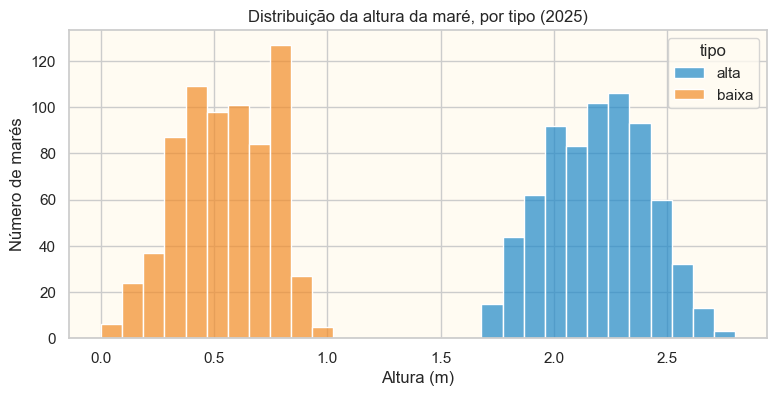

In [363]:
# Como a altura se distribui entre marés altas e baixas?

plt.figure(figsize=(9, 4))
sns.histplot(
    data=df_mares, x="altura", hue="tipo", bins=30,
    palette={"alta": PRAIA["azul"], "baixa": PRAIA["laranja"]}, alpha=0.7,
)
plt.title("Distribuição da altura da maré, por tipo (2025)")
plt.xlabel("Altura (m)")
plt.ylabel("Número de marés")
plt.show()

**Leitura: altura da maré por tipo (2025)**

As duas distribuições estão completamente separadas. As marés baixas ficam entre cerca de 0 e 1,0 m, a maioria entre 0,3 e 0,8 m. As altas ficam entre cerca de 1,7 e 2,8 m, a maioria entre 2,0 e 2,4 m. Não há sobreposição: a faixa entre 1,0 e 1,7 m está vazia, então a altura sozinha já distingue uma maré alta de uma baixa.

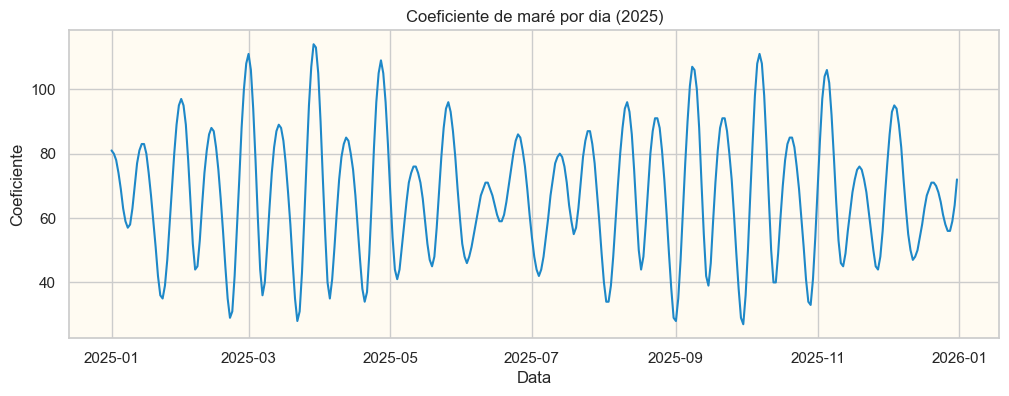

In [364]:
# O coeficiente varia ao longo do ano com algum padrão?

diario = df_mares.drop_duplicates(subset=["ano", "mes", "dia"]).copy()
diario["data"] = diario["datetime"].dt.normalize()

plt.figure(figsize=(12, 4))
sns.lineplot(data=diario, x="data", y="coeficiente", color=PRAIA["azul"])
plt.title("Coeficiente de maré por dia (2025)")
plt.xlabel("Data")
plt.ylabel("Coeficiente")
plt.show()

**Leitura: coeficiente de maré por dia (2025)**

O coeficiente oscila de forma regular durante todo o ano, entre cerca de 27 e 114. Os picos se repetem aproximadamente a cada duas semanas, e os mais altos (acima de 100) aparecem cerca de uma vez por mês, alternando com picos menores (entre 85 e 97). Não há tendência de alta ou de queda de janeiro a dezembro: o ciclo se repete com a mesma amplitude. Qualquer ligação desse ciclo com a fase da lua é só hipótese (ver a nota de limitação abaixo).

**Limitação: relação entre coeficiente e fase da lua**

A fase da lua não foi capturada na coleta: no site ela aparece apenas como um ícone, sem texto, e optei por não extraí-la. Por isso, a pergunta sobre a relação entre o coeficiente de maré e a fase da lua **não pode ser respondida com estes dados**.

O que os dados permitem afirmar é o comportamento do coeficiente ao longo de 2025, descrito no gráfico anterior. Qualquer ligação desse ciclo com a lua seria uma hipótese, e não um resultado desta análise.

count    168.000000
mean       1.218452
std        0.110329
min        0.900000
25%        1.200000
50%        1.200000
75%        1.300000
max        1.400000
Name: altura_onda_m, dtype: float64


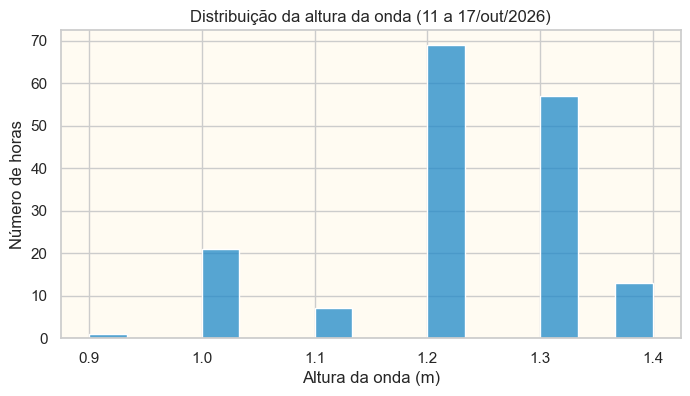

In [365]:
# Qual a faixa de altura na janela coletada?

print(df_ondas["altura_onda_m"].describe())

plt.figure(figsize=(8, 4))
sns.histplot(df_ondas["altura_onda_m"], bins=15, color=PRAIA["azul"])
plt.title("Distribuição da altura da onda (11 a 17/out/2026)")
plt.xlabel("Altura da onda (m)")
plt.ylabel("Número de horas")
plt.show()

**Leitura: altura da onda (11 a 17/out/2026)**

A altura da onda varia entre 0,9 e 1,4 m, com média de 1,22 m e mediana de 1,2 m. A metade central das horas está entre 1,2 e 1,3 m e o desvio padrão é de apenas 0,11 m, então a janela é bastante homogênea. Os valores só aparecem em passos de 0,1 m, o que explica o aspecto em degraus do histograma.

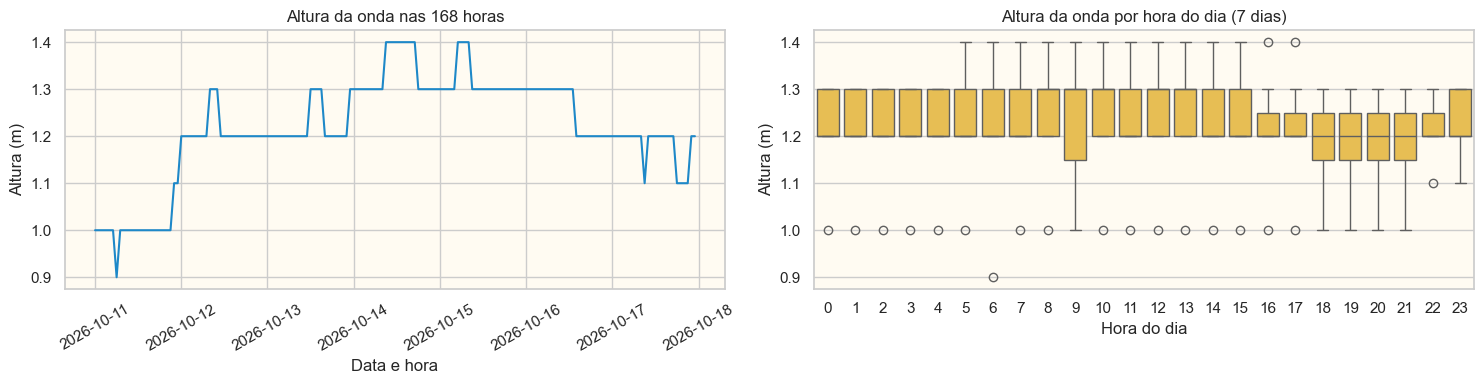

In [366]:
# Há padrão por hora do dia, ou a variação é só por dia?

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

sns.lineplot(data=df_ondas, x="datetime", y="altura_onda_m",
             color=PRAIA["azul"], ax=axes[0])
axes[0].set_title("Altura da onda nas 168 horas")
axes[0].set_xlabel("Data e hora")
axes[0].set_ylabel("Altura (m)")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(x=df_ondas["datetime"].dt.hour, y=df_ondas["altura_onda_m"],
            color=PRAIA["amarelo"], ax=axes[1])
axes[1].set_title("Altura da onda por hora do dia (7 dias)")
axes[1].set_xlabel("Hora do dia")
axes[1].set_ylabel("Altura (m)")

plt.tight_layout()
plt.show()

**Leitura: onda ao longo da janela e por hora do dia**

No gráfico da esquerda, a altura sobe de 1,0 m (dia 11) para 1,2 m a partir do dia 12, chega a 1,3–1,4 m entre os dias 14 e 16 (com picos de 1,4 m nos dias 14 e 15) e volta a 1,2 m a partir da tarde do dia 16, com quedas pontuais a 1,1 m no dia 17.

No da direita, a altura típica é parecida em todas as horas (entre 1,2 e 1,3 m), com caixas um pouco mais baixas entre 18h e 21h. Essa diferença é de 0,1 m, que é a resolução dos dados, e cada caixa tem só 7 pontos. Nesta janela, portanto, a variação é entre dias (uma fase de ondas maiores entre 14 e 16/out), e não por hora do dia. Com 7 dias não dá para afirmar um padrão diário.

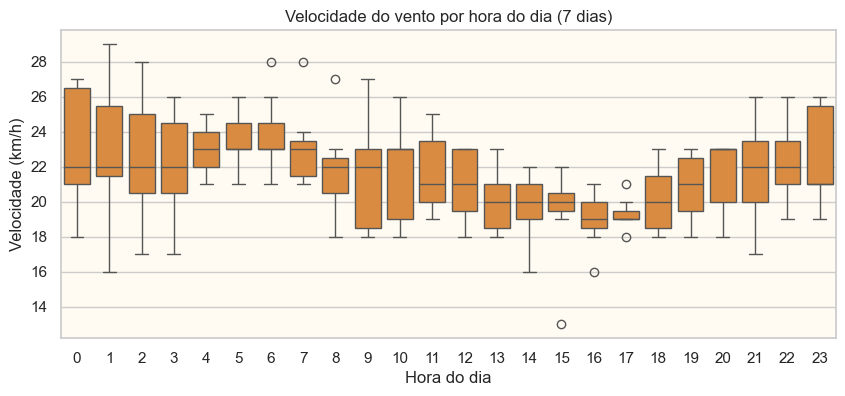

In [367]:
# Quais horas são mais calmas?

plt.figure(figsize=(10, 4))
sns.boxplot(x=df_vento["datetime"].dt.hour, y=df_vento["velocidade_vento_kmh"],
            color=PRAIA["laranja"])
plt.title("Velocidade do vento por hora do dia (7 dias)")
plt.xlabel("Hora do dia")
plt.ylabel("Velocidade (km/h)")
plt.show()

**Leitura: velocidade do vento por hora do dia**

A mediana da velocidade fica em torno de 22–23 km/h da madrugada ao início da manhã (4h às 7h), cai para cerca de 19–20 km/h no meio da tarde e volta a subir ao anoitecer, para cerca de 22 km/h depois das 21h. As horas mais calmas são as da tarde, entre 13h e 17h, com a menor mediana por volta das 16h. A variação ao longo do dia é pequena (cerca de 4 km/h entre as medianas), e mesmo nas horas mais calmas o vento típico é de cerca de 19 km/h. Cada hora tem só 7 observações, então isto é uma tendência da janela, e não uma regra.

<StringArray>
['SE', 'ESE', 'E', 'ENE']
Length: 4, dtype: str


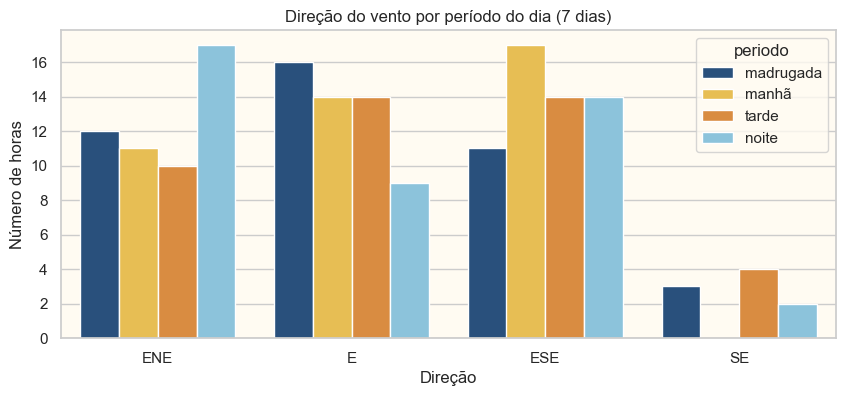

In [368]:
# A direção predominante muda ao longo do dia?

print(df_vento["direcao"].unique())  

periodos = ["madrugada", "manhã", "tarde", "noite"]
vento_p = df_vento.assign(
    periodo=pd.cut(df_vento["datetime"].dt.hour,
                   bins=[-1, 5, 11, 17, 23], labels=periodos)
)

bussola = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
           "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
ordem = [d for d in bussola if d in vento_p["direcao"].unique()]

plt.figure(figsize=(10, 4))
sns.countplot(
    data=vento_p, x="direcao", hue="periodo", order=ordem, hue_order=periodos,
    palette=dict(zip(periodos, [PRAIA["azul_escuro"], PRAIA["amarelo"],
                                PRAIA["laranja"], PRAIA["azul_claro"]])),
)
plt.title("Direção do vento por período do dia (7 dias)")
plt.xlabel("Direção")
plt.ylabel("Número de horas")
plt.show()

**Leitura: direção do vento por período do dia**

Só quatro direções aparecem na janela (ENE, E, ESE e SE), todas do quadrante leste. SE é rara, com cerca de 9 horas das 168. A direção predominante muda um pouco ao longo do dia: à noite é ENE (17 horas), na madrugada passa a E (16 horas), de manhã a ESE (17 horas) e à tarde fica dividida entre E e ESE (14 horas cada). É uma variação de poucos graus, sem inversão de sentido do vento.

## 4. Juntar as tabelas

Esta é a parte difícil, e ela tem mais de uma resposta certa.

As granularidades não batem: onda e vento são leituras horárias; maré são ~4
eventos por dia (os instantes de máxima e mínima). Para ter uma linha por hora
com as três informações você precisa decidir:

- Como levar a maré para a grade horária? Interpolar entre eventos? Repetir o
  último valor? Guardar apenas se a maré está subindo ou descendo? O que cada
  escolha assume sobre a curva real da maré — e onde essa suposição erra?
- Qual o tipo de junção? A previsão de onda e a de vento cobrem exatamente as
  mesmas horas? Se não, você mantém as horas incompletas ou corta?
- Que variáveis derivadas de tempo ajudam a responder a pergunta do projeto
  (dia da semana, período do dia, ...)?

Justifique as escolhas em markdown. Elas são a base das duas próximas etapas.

In [369]:
ondas_sel = df_ondas[["datetime", "direcao", "altura_onda_m"]].rename(
    columns={"direcao": "direcao_onda"}
)
vento_sel = df_vento[["datetime", "direcao", "velocidade_vento_kmh"]].rename(
    columns={"direcao": "direcao_vento"}
)

print("mesmas horas nas duas tabelas:",
      set(ondas_sel["datetime"]) == set(vento_sel["datetime"]))

df_ondas_vento = ondas_sel.merge(
    vento_sel, on="datetime", how="inner", validate="one_to_one"
)

print(len(df_ondas_vento), "linhas")
print(df_ondas_vento.isna().sum())
df_ondas_vento.head()

mesmas horas nas duas tabelas: True
168 linhas
datetime                0
direcao_onda            0
altura_onda_m           0
direcao_vento           0
velocidade_vento_kmh    0
dtype: int64


,datetime,direcao_onda,altura_onda_m,direcao_vento,velocidade_vento_kmh
0,2026-10-11 00:00:00,ESE,1.0,SE,21.0
1,2026-10-11 01:00:00,ESE,1.0,SE,22.0
2,2026-10-11 02:00:00,ESE,1.0,SE,20.0
3,2026-10-11 03:00:00,ESE,1.0,ESE,17.0
4,2026-10-11 04:00:00,ESE,1.0,ESE,21.0


In [370]:
eventos = df_previsao[["datetime", "altura", "tipo"]].sort_values("datetime")
grade = pd.DatetimeIndex(df_ondas_vento["datetime"])

serie = eventos.set_index("datetime")["altura"]
altura_hora = (
    serie.reindex(serie.index.union(grade))
         .interpolate(method="time")
         .reindex(grade)
)

base = grade.to_frame(name="datetime", index=False).sort_values("datetime")
ult = pd.merge_asof(
    base,
    eventos[["datetime", "tipo"]],
    on="datetime",
    direction="backward",
)
ult["sentido"] = ult["tipo"].map({"baixa": "subindo", "alta": "descendo"})

df_dataset = df_ondas_vento.copy()
df_dataset["altura_mare_m"] = df_dataset["datetime"].map(altura_hora)
df_dataset = df_dataset.merge(
    ult[["datetime", "sentido"]], on="datetime", how="left", validate="one_to_one"
)

print(len(df_dataset), "linhas")
print(df_dataset[["altura_mare_m", "sentido"]].isna().sum())
print(df_dataset["sentido"].value_counts())
print("altura: de", df_dataset["altura_mare_m"].min(),
      "até", df_dataset["altura_mare_m"].max())
df_dataset.head()

168 linhas
altura_mare_m    0
sentido          0
dtype: int64
sentido
subindo     85
descendo    83
Name: count, dtype: int64
altura: de 0.3135869565217395 até 2.593766937669377


,datetime,direcao_onda,altura_onda_m,direcao_vento,velocidade_vento_kmh,altura_mare_m,sentido
0,2026-10-11 00:00:00,ESE,1.0,SE,21.0,0.942725,subindo
1,2026-10-11 01:00:00,ESE,1.0,SE,22.0,1.275289,subindo
2,2026-10-11 02:00:00,ESE,1.0,SE,20.0,1.607852,subindo
3,2026-10-11 03:00:00,ESE,1.0,ESE,17.0,1.940416,subindo
4,2026-10-11 04:00:00,ESE,1.0,ESE,21.0,2.272979,subindo


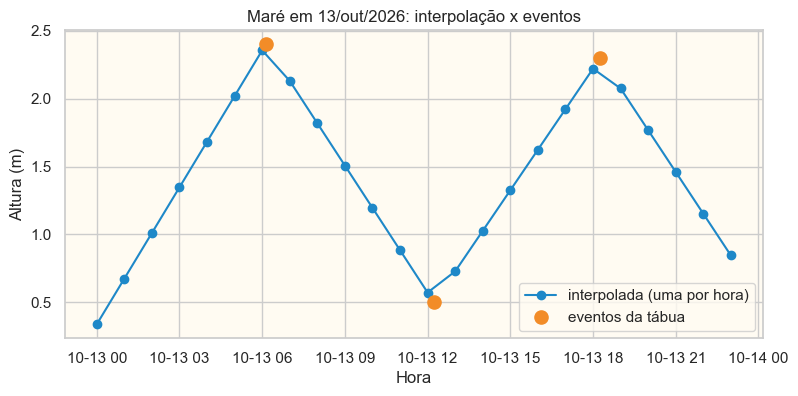

In [371]:
dia = pd.Timestamp("2026-10-13")
h = df_dataset[df_dataset["datetime"].dt.normalize() == dia]
e = eventos[eventos["datetime"].dt.normalize() == dia]

plt.figure(figsize=(9, 4))
plt.plot(h["datetime"], h["altura_mare_m"], color=PRAIA["azul"],
         marker="o", label="interpolada (uma por hora)")
plt.scatter(e["datetime"], e["altura"], color=PRAIA["laranja"],
            s=90, zorder=3, label="eventos da tábua")
plt.title("Maré em 13/out/2026: interpolação x eventos")
plt.xlabel("Hora")
plt.ylabel("Altura (m)")
plt.legend()
plt.show()

In [372]:
df_dataset["hora_dia"] = df_dataset["datetime"].dt.hour
df_dataset["periodo"] = pd.cut(
    df_dataset["hora_dia"],
    bins=[-1, 5, 11, 17, 23],
    labels=["madrugada", "manhã", "tarde", "noite"],
)
df_dataset["dia_semana"] = df_dataset["datetime"].dt.dayofweek  # 0 = segunda, 6 = domingo
df_dataset["fim_de_semana"] = df_dataset["dia_semana"] >= 5

dias = df_previsao.drop_duplicates(subset=["ano", "mes", "dia"]).copy()
dias["data"] = pd.to_datetime(
    dias[["ano", "mes", "dia"]].rename(
        columns={"ano": "year", "mes": "month", "dia": "day"}
    )
)
dias["nascer"] = dias["data"] + pd.to_timedelta(dias["nascer_sol"] + ":00")
dias["por"] = dias["data"] + pd.to_timedelta(dias["por_sol"] + ":00")
dias = dias[["data", "coeficiente", "nascer", "por"]]

df_dataset["data"] = df_dataset["datetime"].dt.normalize()
df_dataset = df_dataset.merge(dias, on="data", how="left", validate="many_to_one")

df_dataset["e_dia"] = (
    (df_dataset["datetime"] >= df_dataset["nascer"])
    & (df_dataset["datetime"] < df_dataset["por"])
)

print(len(df_dataset), "linhas")
print(df_dataset[["coeficiente", "nascer", "por", "e_dia", "periodo"]].isna().sum())
print("horas de dia por data:")
print(df_dataset.groupby("data")["e_dia"].sum())
print("primeiro dia:", df_dataset["datetime"].min().day_name(),
      "| último dia:", df_dataset["datetime"].max().day_name())
print(df_dataset["fim_de_semana"].value_counts())
df_dataset.head()

168 linhas
coeficiente    0
nascer         0
por            0
e_dia          0
periodo        0
dtype: int64
horas de dia por data:
data
2026-10-11    13
2026-10-12    13
2026-10-13    13
2026-10-14    13
2026-10-15    13
2026-10-16    13
2026-10-17    13
Name: e_dia, dtype: int64
primeiro dia: Sunday | último dia: Saturday
fim_de_semana
False    120
True      48
Name: count, dtype: int64


,datetime,direcao_onda,altura_onda_m,direcao_vento,velocidade_vento_kmh,altura_mare_m,sentido,hora_dia,periodo,dia_semana,fim_de_semana,data,coeficiente,nascer,por,e_dia
0,2026-10-11 00:00:00,ESE,1.0,SE,21.0,0.942725,subindo,0,madrugada,6,True,2026-10-11,92,2026-10-11 04:57:00,2026-10-11 17:14:00,False
1,2026-10-11 01:00:00,ESE,1.0,SE,22.0,1.275289,subindo,1,madrugada,6,True,2026-10-11,92,2026-10-11 04:57:00,2026-10-11 17:14:00,False
2,2026-10-11 02:00:00,ESE,1.0,SE,20.0,1.607852,subindo,2,madrugada,6,True,2026-10-11,92,2026-10-11 04:57:00,2026-10-11 17:14:00,False
3,2026-10-11 03:00:00,ESE,1.0,ESE,17.0,1.940416,subindo,3,madrugada,6,True,2026-10-11,92,2026-10-11 04:57:00,2026-10-11 17:14:00,False
4,2026-10-11 04:00:00,ESE,1.0,ESE,21.0,2.272979,subindo,4,madrugada,6,True,2026-10-11,92,2026-10-11 04:57:00,2026-10-11 17:14:00,False


In [373]:
colunas = [
    "datetime", "hora_dia", "periodo", "dia_semana", "fim_de_semana", "e_dia",
    "coeficiente", "altura_mare_m", "sentido",
    "altura_onda_m", "direcao_onda",
    "velocidade_vento_kmh", "direcao_vento",
]
df_dataset = df_dataset[colunas]
df_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   datetime              168 non-null    datetime64[us]
 1   hora_dia              168 non-null    int32         
 2   periodo               168 non-null    category      
 3   dia_semana            168 non-null    int32         
 4   fim_de_semana         168 non-null    bool          
 5   e_dia                 168 non-null    bool          
 6   coeficiente           168 non-null    int64         
 7   altura_mare_m         168 non-null    float64       
 8   sentido               168 non-null    str           
 9   altura_onda_m         168 non-null    float64       
 10  direcao_onda          168 non-null    str           
 11  velocidade_vento_kmh  168 non-null    float64       
 12  direcao_vento         168 non-null    str           
dtypes: bool(2), category(1), dateti

## Decisões de junção (seção 4)

**1. Como levei a maré para a grade horária**

Usei a tábua de marés do mês corrente (`mares_previsao`, outubro de 2026), e não a de 2025, porque a de 2025 não tem nenhum dia da janela de ondas e vento (11 a 17 de outubro). Para cada hora da janela, calculei:

- **Altura da maré**, por interpolação linear no tempo entre os eventos da tábua (altas e baixas). Interpolei com o mês inteiro e só depois recortei a janela de 7 dias, para que as primeiras e últimas horas tivessem um evento antes e um depois.
- **Sentido da maré** (`subindo` ou `descendo`), a partir do tipo do último evento anterior a cada hora: depois de uma baixa a maré sobe, e depois de uma alta ela desce.

Escolhi interpolar porque manter o último valor deixaria a altura errada em quase todas as horas (a maré está sempre mudando), e guardar só o sentido perderia o nível da maré, que é o que permite perguntar se as horas de onda maior coincidem com certa altura de maré. Somei o sentido porque a altura sozinha não distingue uma maré que enche de uma que vaza com o mesmo nível.

*Onde a suposição erra:* a interpolação linear liga os eventos da tábua por retas, então a curva horária forma um "dente de serra" com bicos nos picos. Como os eventos não caem em horas cheias, o ponto horário mais próximo de uma alta fica abaixo dela, e o mais próximo de uma baixa fica acima. No gráfico de 13/10, isso aparece nas duas altas (cerca de 2,36 m contra 2,4 m, perto das 6h, e cerca de 2,22 m contra 2,3 m, perto das 18h) e na baixa (cerca de 0,57 m contra 0,5 m, perto das 12h), com diferenças de poucos centímetros. Por isso, a altura estimada é menos confiável perto dos extremos.

**2. Tipo de junção**

Juntei ondas e vento pela coluna `datetime`, com `merge` do tipo `inner` e `validate="one_to_one"`. As duas previsões cobrem exatamente as mesmas 168 horas (11/out 00:00 a 17/out 23:00), então `inner`, `left` e `outer` dão o mesmo resultado e a escolha foi só de convenção. O `validate` garante que não há horas repetidas. A direção da página de ondas virou `direcao_onda` e a da página de vento virou `direcao_vento`, para não haver conflito de nomes. 

**3. Variáveis derivadas de tempo**

| Variável | Como foi feita | Por que ajuda a pergunta do projeto |
|---|---|---|
| `hora_dia` e `periodo` | hora do `datetime`; madrugada (0 a 5h), manhã (6 a 11h), tarde (12 a 17h), noite (18 a 23h) | os gráficos por hora mostraram diferença de vento entre períodos, então o período permite ranquear horários de forma legível |
| `dia_semana` e `fim_de_semana` | dia da semana do `datetime`; sábado e domingo marcados | a pergunta é sobre quando voltar, e o dia da semana é uma informação prática para quem vai planejar a visita |
| `e_dia` | verdadeiro entre o nascer e o pôr do sol do dia | horas sem luz não são utilizáveis, então esta variável deixa a Etapa 3 descartá-las |
| `coeficiente` | valor do dia, ligado a cada hora pela data | resume o tamanho da variação da maré naquele dia |

Os cortes dos períodos são os mesmos do gráfico de direção do vento, para manter a coerência.

**Resultado:** a tabela `dataset.csv` tem 168 linhas e 13 colunas, sem valores nulos. Cada linha é uma hora de 11 a 17 de outubro de 2026.

**Limitação desta etapa:** o dataset tem apenas 7 dias de dados, então qualquer conclusão sobre "melhores horários" vale só para essa janela.

## 5. Visualizações voltadas à pergunta

Agora com a tabela junta: quando as condições coincidem?

- As horas de onda maior são as mesmas de vento mais fraco, ou elas se
  desencontram?
- Existe relação visível entre altura da maré e altura da onda?
- Quais dias e horas da janela se destacam?

Prefira poucos gráficos legíveis a muitos gráficos.

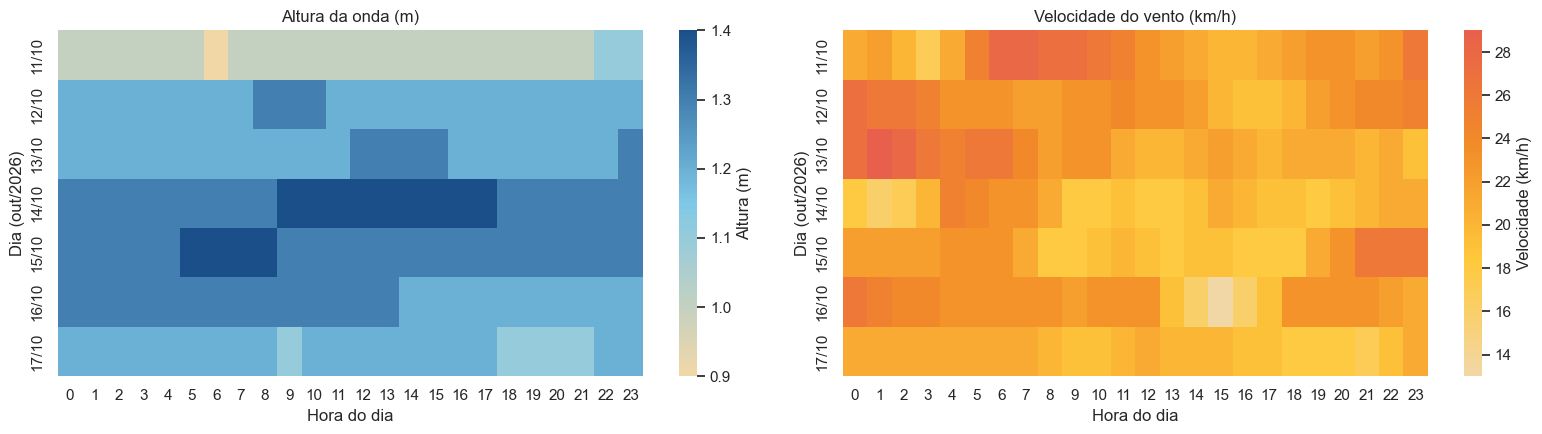

In [374]:
# As horas de onda maior são as mesmas de vento mais fraco, ou elas se desencontram?

from matplotlib.colors import LinearSegmentedColormap

cmap_onda = LinearSegmentedColormap.from_list(
    "onda", [PRAIA["areia"], PRAIA["azul_claro"], PRAIA["azul_escuro"]]
)
cmap_vento = LinearSegmentedColormap.from_list(
    "vento", [PRAIA["areia"], PRAIA["amarelo"], PRAIA["laranja"], PRAIA["coral"]]
)

d = df_dataset.assign(dia=df_dataset["datetime"].dt.strftime("%d/%m"))
onda_m = d.pivot(index="dia", columns="hora_dia", values="altura_onda_m")
vento_m = d.pivot(index="dia", columns="hora_dia", values="velocidade_vento_kmh")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

sns.heatmap(onda_m, cmap=cmap_onda, ax=axes[0], cbar_kws={"label": "Altura (m)"})
axes[0].set_title("Altura da onda (m)")

sns.heatmap(vento_m, cmap=cmap_vento, ax=axes[1], cbar_kws={"label": "Velocidade (km/h)"})
axes[1].set_title("Velocidade do vento (km/h)")

for ax in axes:
    ax.set_xlabel("Hora do dia")
    ax.set_ylabel("Dia (out/2026)")
    ax.grid(False)

plt.tight_layout()
plt.show()

**Leitura: onda e vento, hora a hora (11 a 17/out)**

A onda varia sobretudo entre dias: em 11/10 fica em torno de 1,0 m; em 12 e 13/10, em torno de 1,2 m; em 14 e 15/10 chega a 1,3–1,4 m (o máximo de 1,4 m aparece em 14/10, das 9h às 17h, e em 15/10, das 5h às 8h); e em 16 e 17/10 volta a 1,2–1,3 m. O vento varia mais ao longo do dia: na maior parte dos dias a faixa da tarde (cerca de 13h às 17h) é mais clara, isto é, de vento mais fraco, que a madrugada. O vento mais fraco da janela (cerca de 13 km/h) ocorre em 16/10 por volta das 15h.

Os dois coincidem em parte e se desencontram em parte. Entre dias, os de onda maior (14 e 15/10) são também os de vento mais baixo, e o dia de onda menor (11/10) tem o vento mais forte. Dentro do dia, porém, o horário de vento mais fraco nem sempre cai na hora de onda maior: o mínimo de 13 km/h (16/10, 15h) acontece com onda de 1,2 m, abaixo do máximo da janela.

Ressalva: são só 7 dias. As diferenças são de poucos décimos de metro na onda e de poucos km/h no vento, então esta coincidência entre dias não prova uma relação.

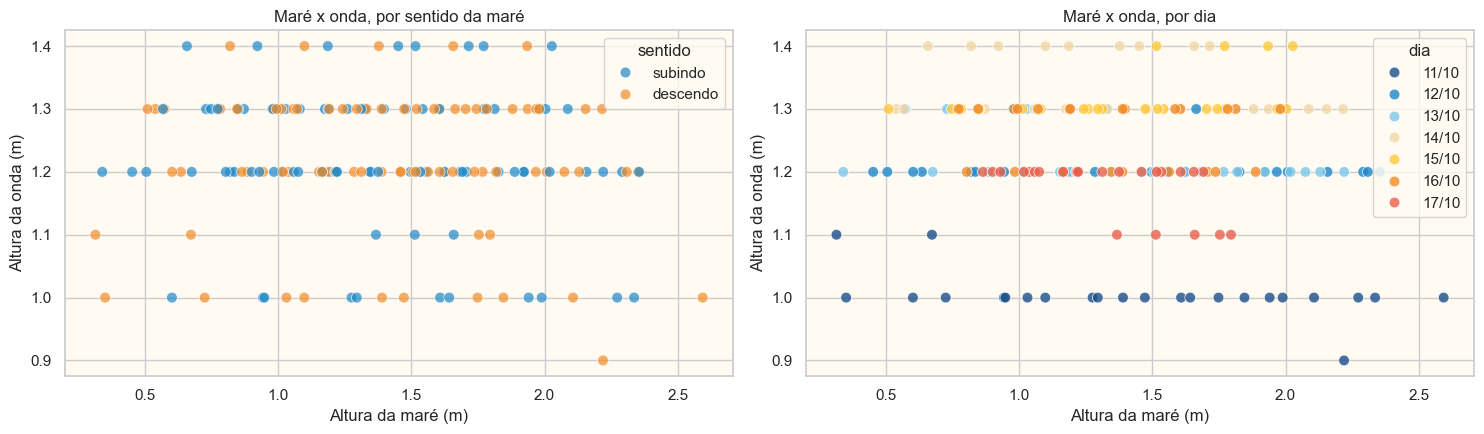

               altura_mare_m  altura_onda_m
altura_mare_m       1.000000      -0.104019
altura_onda_m      -0.104019       1.000000


In [375]:
# Existe relação visível entre altura da maré e altura da onda?

d = df_dataset.assign(dia=df_dataset["datetime"].dt.strftime("%d/%m"))
cores_dias = [PRAIA["azul_escuro"], PRAIA["azul"], PRAIA["azul_claro"],
              PRAIA["areia"], PRAIA["amarelo"], PRAIA["laranja"], PRAIA["coral"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

sns.scatterplot(
    data=d, x="altura_mare_m", y="altura_onda_m", hue="sentido",
    palette={"subindo": PRAIA["azul"], "descendo": PRAIA["laranja"]},
    alpha=0.7, s=60, ax=axes[0],
)
axes[0].set_title("Maré x onda, por sentido da maré")

sns.scatterplot(
    data=d, x="altura_mare_m", y="altura_onda_m", hue="dia",
    palette=cores_dias, alpha=0.8, s=60, ax=axes[1],
)
axes[1].set_title("Maré x onda, por dia")

for ax in axes:
    ax.set_xlabel("Altura da maré (m)")
    ax.set_ylabel("Altura da onda (m)")

plt.tight_layout()
plt.show()

print(d[["altura_mare_m", "altura_onda_m"]].corr())

**Leitura: altura da maré x altura da onda**

Não há relação visível entre a altura da maré e a da onda. No painel da esquerda, os pontos formam faixas horizontais, porque a onda só aparece em passos de 0,1 m. Em cada faixa a maré cobre quase toda a sua amplitude, de cerca de 0,3 a 2,6 m, e as marés subindo e descendo ficam misturadas, sem tendência. A correlação é de -0,10, muito fraca.

No painel da direita, os mesmos pontos coloridos por dia mostram que cada dia ocupa a sua própria faixa de altura de onda (11/10 em cerca de 1,0 m; 12 e 13/10 em cerca de 1,2 m; 14 e 15/10 em 1,3–1,4 m; 16/10 em 1,2–1,3 m; 17/10 em cerca de 1,2 m), enquanto a maré percorre toda a amplitude dentro de cada dia. A altura da onda depende, portanto, do dia, e não da maré.

Ressalva: a correlação não serve como prova, porque horas vizinhas são parecidas e há bem menos de 168 observações independentes. Com apenas 7 dias, não dá para separar um efeito da maré de um efeito do dia.

     dia  onda_media  onda_max  vento_medio  vento_min
0  11/10        0.99       1.0        24.08       20.0
1  12/10        1.22       1.3        22.00       19.0
2  13/10        1.23       1.3        22.23       20.0
3  14/10        1.37       1.4        20.08       18.0
4  15/10        1.33       1.4        19.46       18.0
5  16/10        1.27       1.3        20.46       13.0
6  17/10        1.19       1.2        20.00       19.0


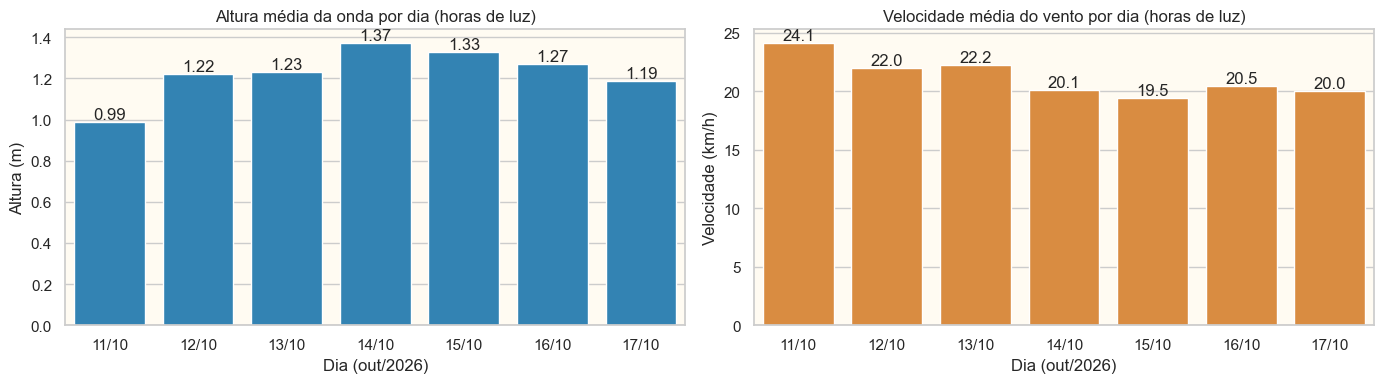

               datetime  altura_onda_m  velocidade_vento_kmh  altura_mare_m  \
81  2026-10-14 09:00:00            1.4                  18.0       1.657260   
82  2026-10-14 10:00:00            1.4                  18.0       1.377808   
84  2026-10-14 12:00:00            1.4                  18.0       0.818904   
85  2026-10-14 13:00:00            1.4                  18.0       0.657300   
104 2026-10-15 08:00:00            1.4                  18.0       1.934615   
83  2026-10-14 11:00:00            1.4                  19.0       1.098356   
86  2026-10-14 14:00:00            1.4                  19.0       0.921763   
89  2026-10-14 17:00:00            1.4                  19.0       1.715152   
88  2026-10-14 16:00:00            1.4                  20.0       1.450689   
87  2026-10-14 15:00:00            1.4                  21.0       1.186226   

      sentido  
81   descendo  
82   descendo  
84   descendo  
85    subindo  
104  descendo  
83   descendo  
86    subindo  
89

In [376]:
# Quais dias e horas da janela se destacam?

base = df_dataset[df_dataset["e_dia"]].copy()
base["dia"] = base["datetime"].dt.strftime("%d/%m")

resumo = base.groupby("dia").agg(
    onda_media=("altura_onda_m", "mean"),
    onda_max=("altura_onda_m", "max"),
    vento_medio=("velocidade_vento_kmh", "mean"),
    vento_min=("velocidade_vento_kmh", "min"),
).round(2).reset_index()
print(resumo)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=resumo, x="dia", y="onda_media", color=PRAIA["azul"], ax=axes[0])
axes[0].set_title("Altura média da onda por dia (horas de luz)")
axes[0].set_ylabel("Altura (m)")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")

sns.barplot(data=resumo, x="dia", y="vento_medio", color=PRAIA["laranja"], ax=axes[1])
axes[1].set_title("Velocidade média do vento por dia (horas de luz)")
axes[1].set_ylabel("Velocidade (km/h)")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")

for ax in axes:
    ax.set_xlabel("Dia (out/2026)")

plt.tight_layout()
plt.show()

ranking = base.sort_values(
    ["altura_onda_m", "velocidade_vento_kmh"], ascending=[False, True]
)
print(ranking[["datetime", "altura_onda_m", "velocidade_vento_kmh",
               "altura_mare_m", "sentido"]].head(10))

**Leitura: dias e horas que se destacam (só horas de luz)**

Considerando apenas as 13 horas de luz de cada dia, o dia 14/10 tem a maior onda média (1,37 m), com vento médio de 20,1 km/h. O dia 15/10 vem logo depois em onda (1,33 m) e tem o menor vento médio da janela (19,5 km/h). O outro extremo é 11/10, com a menor onda média (0,99 m) e o maior vento médio (24,1 km/h).

A onda de 1,4 m, o máximo da janela, aparece só em 14/10 (das 9h às 17h) e em 15/10 (das 5h às 8h). As 10 horas do ranking (onda de 1,4 m, ordenadas pelo vento mais fraco, de 18 a 21 km/h) são 9 de 14/10 e 1 de 15/10 (às 8h). Nelas a maré aparece subindo e descendo em igual número (5 e 5) e em alturas variadas, de cerca de 0,7 a 1,9 m. O destaque é, portanto, do dia, e não de um horário específico nem de uma fase da maré.

Ressalva: o destaque vale só para esta janela de 7 dias, e as diferenças entre os dias são pequenas (décimos de metro e poucos km/h).

## 6. Salvar o dataset processado

Grave o resultado em `../data/processed/dataset.csv`. A Etapa 3 lê esse
arquivo — se as colunas mudarem depois, o notebook de ML muda também.

In [377]:
saida = df_dataset.copy()
saida["altura_mare_m"] = saida["altura_mare_m"].round(2)  

saida.to_csv(DIR_PROC / "dataset.csv", index=False)

lido = pd.read_csv(DIR_PROC / "dataset.csv", parse_dates=["datetime"])

print("formato:", lido.shape)
print("mesmas colunas e mesma ordem:", list(lido.columns) == list(saida.columns))
print("nulos no total:", lido.isna().sum().sum())
print("mesmo intervalo:", lido["datetime"].min(), "até", lido["datetime"].max())
lido.info()
lido.head()

formato: (168, 13)
mesmas colunas e mesma ordem: True
nulos no total: 0
mesmo intervalo: 2026-10-11 00:00:00 até 2026-10-17 23:00:00
<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   datetime              168 non-null    datetime64[us]
 1   hora_dia              168 non-null    int64         
 2   periodo               168 non-null    str           
 3   dia_semana            168 non-null    int64         
 4   fim_de_semana         168 non-null    bool          
 5   e_dia                 168 non-null    bool          
 6   coeficiente           168 non-null    int64         
 7   altura_mare_m         168 non-null    float64       
 8   sentido               168 non-null    str           
 9   altura_onda_m         168 non-null    float64       
 10  direcao_onda          168 non-null    str           
 11  velocidade_ven

,datetime,hora_dia,periodo,dia_semana,fim_de_semana,e_dia,coeficiente,altura_mare_m,sentido,altura_onda_m,direcao_onda,velocidade_vento_kmh,direcao_vento
0,2026-10-11 00:00:00,0,madrugada,6,True,False,92,0.94,subindo,1.0,ESE,21.0,SE
1,2026-10-11 01:00:00,1,madrugada,6,True,False,92,1.28,subindo,1.0,ESE,22.0,SE
2,2026-10-11 02:00:00,2,madrugada,6,True,False,92,1.61,subindo,1.0,ESE,20.0,SE
3,2026-10-11 03:00:00,3,madrugada,6,True,False,92,1.94,subindo,1.0,ESE,17.0,ESE
4,2026-10-11 04:00:00,4,madrugada,6,True,False,92,2.27,subindo,1.0,ESE,21.0,ESE


## 7. Conclusões

Em texto, sem código:

1. O que os dados mostram sobre as condições da janela coletada?
2. Que decisão de limpeza ou de junção você tomou que mais influencia o
   resultado, e por quê?
3. O que esses dados **não** permitem afirmar?

**1. O que os dados mostram sobre as condições da janela coletada**

Na janela de 11 a 17/out/2026 (168 horas), as condições foram bastante homogêneas:

- **Onda:** altura entre 0,9 e 1,4 m, com média de 1,22 m. A metade central das horas ficou entre 1,2 e 1,3 m. A variação foi sobretudo entre dias: cerca de 1,0 m em 11/10, 1,2 m em 12 e 13/10, 1,3–1,4 m em 14 e 15/10 e de volta a 1,2 m em 17/10. Dentro do dia, a altura praticamente não muda com a hora.
- **Vento:** velocidade entre 13 e 29 km/h, sempre de direções do quadrante leste (ENE, E e ESE, com SE rara). É mais fraco na tarde (cerca de 13h às 17h) e mais forte na madrugada e no início da manhã, mas mesmo nas horas mais calmas o vento típico é de cerca de 19 km/h.
- **Maré:** a altura horária estimada varia de cerca de 0,3 a 2,6 m. Não há relação visível entre a altura da maré e a da onda (correlação de -0,10): cada dia ocupa a sua própria faixa de onda, enquanto a maré percorre toda a amplitude dentro do dia.
- **Dias que se destacam:** 14/10 (onda média de 1,37 m, vento médio de 20,1 km/h) e 15/10 (1,33 m e 19,5 km/h) reúnem as maiores ondas e os ventos mais baixos. A onda de 1,4 m, o máximo da janela, aparece só em 14/10 (das 9h às 17h) e em 15/10 (das 5h às 8h). O dia 11/10 é o oposto: a menor onda (0,99 m) e o vento mais forte (24,1 km/h).

**2. A decisão de limpeza ou de junção que mais influencia o resultado**

A decisão que mais pesa é a forma de levar a maré para a grade horária: interpolei linearmente a altura entre os eventos da tábua do mês (`mares_previsao`) e derivei o sentido (subindo ou descendo) do último evento. Escolhi isso porque as granularidades não batem (a maré tem cerca de 4 eventos por dia, e a onda e o vento são horários), e porque repetir o último valor deixaria a altura errada em quase todas as horas, enquanto guardar só o sentido perderia o nível da maré.

A consequência é que `altura_mare_m` é uma estimativa, e não uma medida. No gráfico de 13/10, a interpolação erra em poucos centímetros perto das altas e da baixa (os pontos horários ficam um pouco abaixo dos picos e acima do vale), porque as retas entre os eventos não reproduzem a curva arredondada da maré. É a coluna que sustenta a análise de maré x onda, mas como o erro é pequeno diante da amplitude de cerca de 2 m e a onda varia por dia, é improvável que a conclusão de ausência de relação dependa dele.

Duas escolhas relacionadas também influenciam o que aparece: usei a tábua do mês corrente e não a de 2025, porque a de 2025 não tem nenhum dia da janela, e nos resumos por dia e no ranking considerei só as horas de luz (`e_dia`), o que muda quais horas aparecem como destaque.

**3. O que esses dados não permitem afirmar**

- **Nada sobre o resto do ano.** As ondas e o vento cobrem apenas 7 dias (11 a 17/out/2026). A pergunta do projeto é sobre quando voltar, mas estes dados não dizem como as condições variam entre meses ou estações. A tábua de 2025 cobre o ano inteiro, mas só para a maré, e não se cruza com as previsões.
- **Relação entre coeficiente e fase da lua.** A lua não foi capturada na coleta (no site ela é só um ícone sem texto). O ciclo do coeficiente em 2025 é descritivo, e qualquer ligação com a lua seria hipótese.
- **Causa entre maré, onda e vento.** Com 7 dias, não dá para separar o efeito da maré do efeito do dia. Horas vizinhas são parecidas entre si, então há bem menos de 168 observações independentes, e a correlação de -0,10 não prova nada.
- **Padrões por hora do dia.** Cada hora tem só 7 observações, então as diferenças entre horas (como o vento mais fraco à tarde) são tendências desta janela, e não regras.
- **Qualidade de uma onda para o surfe.** O dataset não tem um rótulo de "boa" ou "ruim", e a coleta tem só a altura e a direção da onda, sem outras variáveis que influenciam a prática (como o período da onda ou as condições do pico). Os destaques descrevem onde onda e vento coincidem, e não onde o surfe é bom.
- **Valores medidos.** Onda e vento são previsões, a maré vem de uma tábua e a altura horária da maré é estimada por interpolação. A altura da onda só aparece em passos de 0,1 m, então diferenças menores que isso não são visíveis.